--- Data Structure ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9550 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Price range           9551 non-null   int64  
 15

None

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,Average Cost for two,Currency,Has Table booking,Has Online delivery,Price range,Aggregate rating,Rating color,Rating text,Votes
0,7402935,Skye,94,Jakarta,"Menara BCA, Lantai 56, Jl. MH. Thamrin, Thamri...","Grand Indonesia Mall, Thamrin","Grand Indonesia Mall, Thamrin, Jakarta",106.821999,-6.196778,"Italian, Continental",800000,Indonesian Rupiah(IDR),No,No,3,4.1,Green,Very Good,1498
1,7410290,Satoo - Hotel Shangri-La,94,Jakarta,"Hotel Shangri-La, Jl. Jend. Sudirman","Hotel Shangri-La, Sudirman","Hotel Shangri-La, Sudirman, Jakarta",106.818961,-6.203292,"Asian, Indonesian, Western",800000,Indonesian Rupiah(IDR),No,No,3,4.6,Dark Green,Excellent,873
2,7420899,Sushi Masa,94,Jakarta,"Jl. Tuna Raya No. 5, Penjaringan",Penjaringan,"Penjaringan, Jakarta",106.800144,-6.101298,"Sushi, Japanese",500000,Indonesian Rupiah(IDR),No,No,3,4.9,Dark Green,Excellent,605
3,7421967,3 Wise Monkeys,94,Jakarta,"Jl. Suryo No. 26, Senopati, Jakarta",Senopati,"Senopati, Jakarta",106.813400,-6.235241,Japanese,450000,Indonesian Rupiah(IDR),No,No,3,4.2,Green,Very Good,395
4,7422489,Avec Moi Restaurant and Bar,94,Jakarta,"Gedung PIC, Jl. Teluk Betung 43, Thamrin, Jakarta",Thamrin,"Thamrin, Jakarta",106.821023,-6.196270,"French, Western",350000,Indonesian Rupiah(IDR),No,No,3,4.3,Green,Very Good,243



--- Missing Values ---
Restaurant ID           0
Restaurant Name         1
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

--- Duplicates ---
Total duplicate rows: 0

City with MAXIMUM restaurants: New Delhi (5473)
City with MINIMUM restaurants: Miller (1)


/tmp/ipykernel_2286/3004525744.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=city_counts.head(15).index, y=city_counts.head(15).values, palette='viridis')


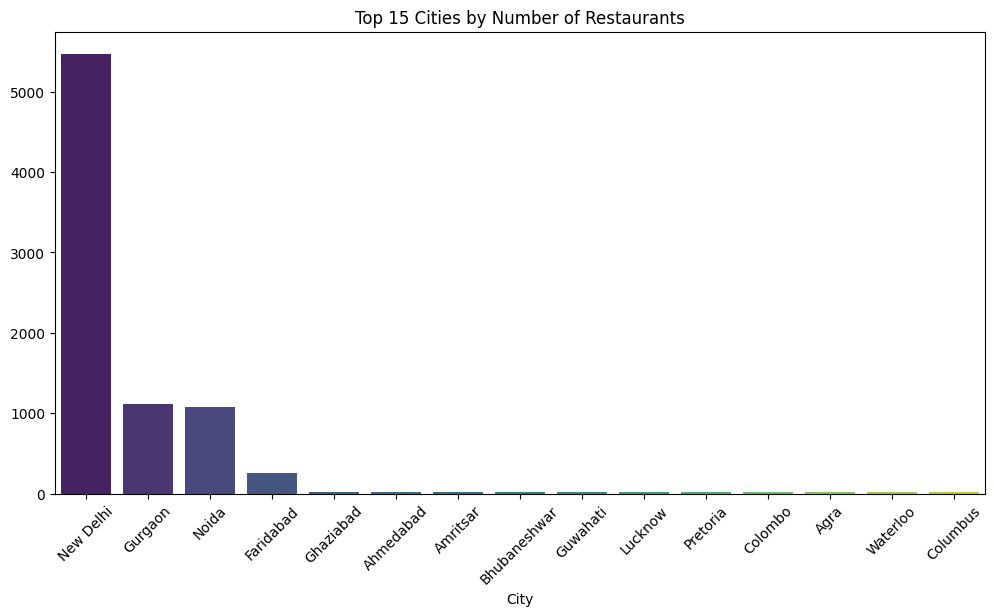


Franchise with most national presence: Cafe Coffee Day (83 locations)

--- Table Booking Ratio ---
Has Table booking
No     0.878756
Yes    0.121244
Name: proportion, dtype: float64


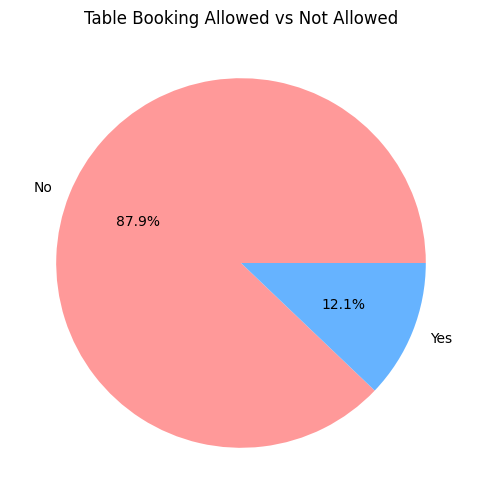


--- Online Delivery Percentage ---
Has Online delivery
No     74.337766
Yes    25.662234
Name: proportion, dtype: float64

--- Average Votes by Delivery Option ---
Has Online delivery
No     138.131127
Yes    211.307222
Name: Votes, dtype: float64
Difference in average votes: 73.18


/tmp/ipykernel_2286/3004525744.py:65: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"Difference in average votes: {abs(votes_delivery[0] - votes_delivery[1]):.2f}")


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Importing the Data
df = pd.read_excel('data.xlsx')

# --- PRELIMINARY DATA INSPECTION ---

print("--- Data Structure ---")
display(df.info())
display(df.head())

print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Duplicates ---")
duplicates_count = df.duplicated().sum()
print(f"Total duplicate rows: {duplicates_count}")

# Cleaning: Drop duplicates
if duplicates_count > 0:
    df = df.drop_duplicates()
    print("Duplicates removed.")

# --- PERFORMING EDA ---

# 1. Geographical Distribution (Max and Min Cities)
city_counts = df['City'].value_counts()
print(f"\nCity with MAXIMUM restaurants: {city_counts.index[0]} ({city_counts.iloc[0]})")
print(f"City with MINIMUM restaurants: {city_counts.index[-1]} ({city_counts.iloc[-1]})")

# Plotting top 15 cities
plt.figure(figsize=(12, 6))
sns.barplot(x=city_counts.head(15).index, y=city_counts.head(15).values, palette='viridis')
plt.xticks(rotation=45)
plt.title('Top 15 Cities by Number of Restaurants')
plt.show()

# 2. Franchise with Most National Presence
# Assuming franchise name is under 'Restaurant Name'
franchise_counts = df['Restaurant Name'].value_counts()
print(f"\nFranchise with most national presence: {franchise_counts.index[0]} ({franchise_counts.iloc[0]} locations)")

# 3. Ratio of Table Booking
booking_ratio = df['Has Table booking'].value_counts(normalize=True)
print("\n--- Table Booking Ratio ---")
print(booking_ratio)

# Plotting Booking Ratio
plt.figure(figsize=(6, 6))
plt.pie(booking_ratio, labels=booking_ratio.index, autopct='%1.1f%%', colors=['#ff9999','#66b3ff'])
plt.title('Table Booking Allowed vs Not Allowed')
plt.show()

# 4. Percentage Providing Online Delivery
delivery_pct = df['Has Online delivery'].value_counts(normalize=True) * 100
print("\n--- Online Delivery Percentage ---")
print(delivery_pct)

# 5. Difference in Votes: Delivery vs. Non-Delivery
votes_delivery = df.groupby('Has Online delivery')['Votes'].mean()
print("\n--- Average Votes by Delivery Option ---")
print(votes_delivery)
print(f"Difference in average votes: {abs(votes_delivery[0] - votes_delivery[1]):.2f}")

week 2


/tmp/ipykernel_2286/835595803.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Cuisine_Count', y='Aggregate rating', data=df, palette='Set2')


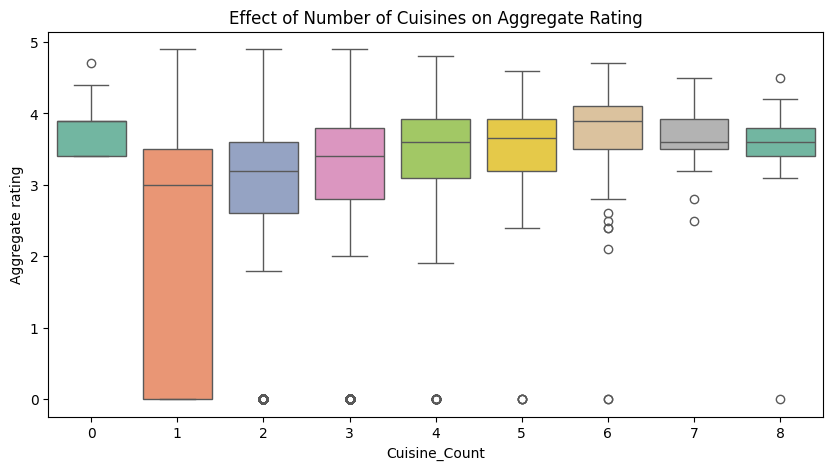

/tmp/ipykernel_2286/835595803.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x='Has Online delivery', y='Aggregate rating', data=df, palette='muted')


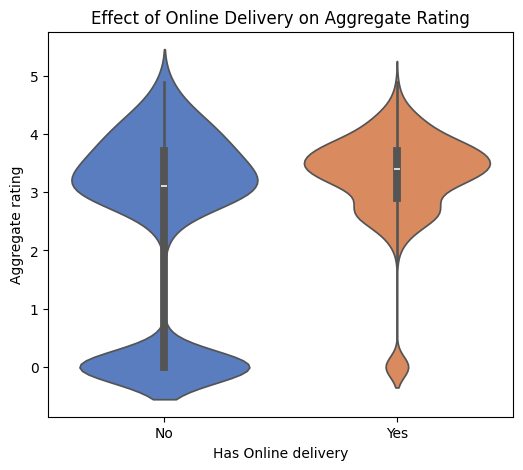

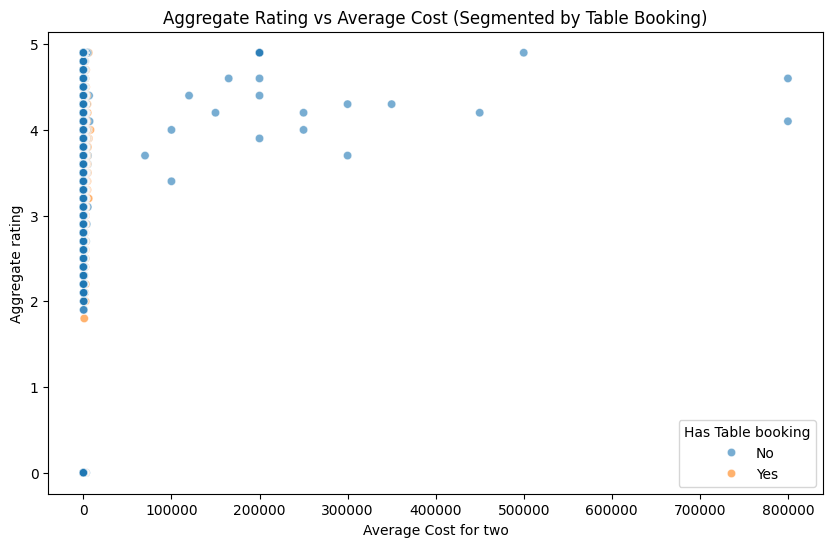

In [4]:
# 4. Rating vs Number of Cuisines

# Create the Cuisine_Count column first
df['Cuisine_Count'] = df['Cuisines'].apply(lambda x: len(str(x).split(',')) if pd.notna(x) else 0)

# Now generate the plot
plt.figure(figsize=(10, 5))
sns.boxplot(x='Cuisine_Count', y='Aggregate rating', data=df, palette='Set2')
plt.title('Effect of Number of Cuisines on Aggregate Rating')
plt.show()

# Rating vs Online Delivery
plt.figure(figsize=(6, 5))
sns.violinplot(x='Has Online delivery', y='Aggregate rating', data=df, palette='muted')
plt.title('Effect of Online Delivery on Aggregate Rating')
plt.show()

# Rating vs Cost (Using a scatter plot to view the spread)
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Average Cost for two', y='Aggregate rating', hue='Has Table booking', alpha=0.6, data=df)
plt.title('Aggregate Rating vs Average Cost (Segmented by Table Booking)')
plt.show()

Exporting cleaned data set

In [5]:
df.to_csv('zomato_cleaned.csv', index=False)